# Sombra: o calor perigoso das próximas 24 horas

**GS 2026.2 · IA & Machine Learning** · André Nakamatsu Rocha (RM555004) · João Marcelo Furtado Romero (RM555199) · Matheus Rivera Montovaneli (RM555499)

## 1. O problema e os dados

Em ondas de calor, a pessoa idosa que mora sozinha corre mais risco: sente menos sede e quase nunca percebe que a casa virou um forno. O Sombra quer avisar a família **antes** do pior momento, e não depois. Daí a pergunta deste notebook:

> **Com o que a estação do INMET mediu nas últimas 24 horas, o índice de calor em São Paulo vai chegar ao nível de risco nas próximas 24 horas?**

É uma classificação binária. Não avisar num dia perigoso custa mais do que um aviso a mais, então olhamos primeiro para o **recall**, sem esquecer o custo dos alarmes falsos: na entrevista, a família pediu para não receber alerta à toa.

**Fonte:** INMET, dados históricos horários ([portal.inmet.gov.br/dadoshistoricos](https://portal.inmet.gov.br/dadoshistoricos)), estação automática **A701, São Paulo – Mirante de Santana**, 2010 a 2025. São medições reais e públicas; nada aqui é simulado. Proveniência e SHA-256 de cada arquivo em [`dados/README.md`](../dados/README.md).

In [1]:
import re
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown as MarkdownBruto
from IPython.display import display

from sombra_ml import figuras as fig
from sombra_ml.dados import FUSO_LOCAL, carregar_brutos, conferir_manifesto, limpar
from sombra_ml.features import CATALOGO, LIMIAR_ALVO_C, NOMES_DAS_FEATURES, montar_amostras, orvalho_c, series_base
from sombra_ml.indice_calor import LIMIARES_C

fig.aplicar_estilo()


def Markdown(texto):
    """Texto de resultado com a vírgula decimal do português."""
    return MarkdownBruto(re.sub(r"(?<=\d)\.(?=\d)", ",", texto))


pd.options.display.float_format = "{:,.3f}".format
BRUTOS = RAIZ / "dados" / "brutos"

conferir_manifesto(BRUTOS)  # falha se algum CSV não for o que veio do INMET
bruto = carregar_brutos(BRUTOS)
print(f"{len(bruto):,} horas · {bruto.index.min():%d/%m/%Y} a {bruto.index.max():%d/%m/%Y} (UTC) · {bruto.shape[1]} medições")
bruto.describe().T[["count", "mean", "min", "max"]]

140,256 horas · 01/01/2010 a 31/12/2025 (UTC) · 7 medições


,count,mean,min,max
temperatura_c,"139,363.000",20.539,4.100,37.300
umidade_pct,"139,514.000",69.306,12.000,100.000
orvalho_inmet_c,"139,512.000",14.034,-6.900,25.400
pressao_hpa,"139,516.000",927.155,913.100,940.300
radiacao_kj_m2,"74,300.000","1,296.218",0.000,"3,999.600"
vento_ms,"139,513.000",1.846,0.000,10.900
chuva_mm,"139,077.000",0.180,0.000,82.000


## 2. Limpeza

Regras, todas em funções testadas (`sombra_ml/dados.py`, `tests/test_dados.py`):

- `-9999` e campo vazio viram **ausente**: o INMET usa esse código para falha de sensor ou de transmissão.
- O horário vem em **UTC**; dias, horas e estações são calculados em `America/Sao_Paulo`.
- Buracos de **até 3 h** em grandezas contínuas são interpolados. Chuva e radiação não, porque são acumulados da hora.
- **Dias locais com mais de 25% faltando** são descartados.
- Uma hora interpolada **nunca vira amostra**. Assim, nenhuma amostra usa, nem indiretamente, um valor posterior a ela.

In [2]:
limpa, relatorio = limpar(bruto)
pd.DataFrame(
    {"ausentes na origem": relatorio.ausentes_na_origem, "fora da faixa física": relatorio.fora_da_faixa}
).assign(**{"% ausente": lambda t: 100 * t["ausentes na origem"] / relatorio.horas})

,ausentes na origem,fora da faixa física,% ausente
temperatura_c,893,0,0.637
umidade_pct,742,0,0.529
orvalho_inmet_c,744,0,0.530
pressao_hpa,740,0,0.528
radiacao_kj_m2,65956,0,47.025
vento_ms,743,0,0.530
chuva_mm,1179,0,0.841


In [3]:
display(Markdown(
    f"- Horas interpoladas (temperatura): **{relatorio.horas_interpoladas}**\n"
    f"- Dias locais descartados: **{relatorio.dias_descartados}** ({relatorio.horas_descartadas} horas)\n"
    f"- Horas realmente medidas e aproveitadas: **{limpa['observada'].mean():.1%}**\n\n"
    "A radiação tem muitos ausentes porque o INMET não a informa à noite; por isso ela entra só como soma na janela."
))

- Horas interpoladas (temperatura): **160**
- Dias locais descartados: **40** (960 horas)
- Horas realmente medidas e aproveitadas: **99,2%**

A radiação tem muitos ausentes porque o INMET não a informa à noite; por isso ela entra só como soma na janela.

## 3. O alvo: qual limiar é possível nos dados reais?

O índice de calor segue a equação da NWS, com os mesmos 20 vetores de teste usados em C#, Java, C++ e TypeScript. O alvo é `1` quando o **máximo das próximas 24 horas** alcança o limiar. A tabela da NWS oferece duas âncoras: `CAUTELA_EXTREMA` (32,22 °C) e `PERIGO` (39,44 °C). A escolha olha **só o período de treino**.

In [4]:
base = series_base(limpa)
amostras = montar_amostras(limpa)
ano_local = amostras.index.tz_convert(FUSO_LOCAL).year
pico_treino = amostras.loc[ano_local <= 2021, "pico_futuro_c"]
linhas = [("ATENCAO", LIMIARES_C["ATENCAO"]), ("CAUTELA_EXTREMA", LIMIARES_C["CAUTELA_EXTREMA"]), ("PERIGO", LIMIARES_C["PERIGO"])]
pd.DataFrame(
    [{"nível (NWS)": n, "limiar (°C)": v, "amostras positivas": int((pico_treino >= v).sum()), "% positivas": 100 * (pico_treino >= v).mean()} for n, v in linhas]
)

,nível (NWS),limiar (°C),amostras positivas,% positivas
0,ATENCAO,26.670,7456,42.927
1,CAUTELA_EXTREMA,32.220,430,2.476
2,PERIGO,39.440,0,0.000


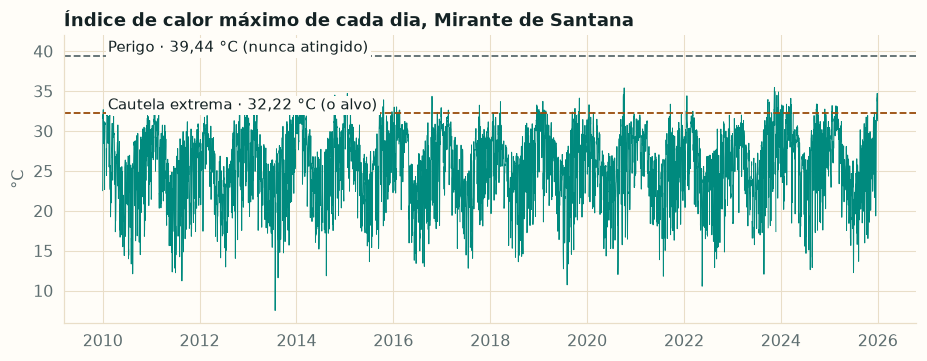

In [5]:
diario = base["indice_calor_c"].tz_convert(FUSO_LOCAL).resample("D").max()
figura, eixo = plt.subplots(figsize=(10, 3.4))
eixo.plot(diario.index, diario, color=fig.PERSISTENCIA, linewidth=0.6)
for nome, cor, texto in [("CAUTELA_EXTREMA", fig.LIMIAR, "Cautela extrema · 32,22 °C (o alvo)"), ("PERIGO", fig.TINTA_SUAVE, "Perigo · 39,44 °C (nunca atingido)")]:
    eixo.axhline(LIMIARES_C[nome], color=cor, linewidth=1.2, linestyle="--")
    eixo.text(diario.index[40], LIMIARES_C[nome] + 0.5, texto, color=fig.TINTA, fontsize=9.5, bbox={"facecolor": fig.FUNDO, "edgecolor": "none", "pad": 1.5})
eixo.set_title("Índice de calor máximo de cada dia, Mirante de Santana")
eixo.set_ylabel("°C")
eixo.set_ylim(top=42)
fig.salvar(figura, "01_indice_diario")
plt.show()

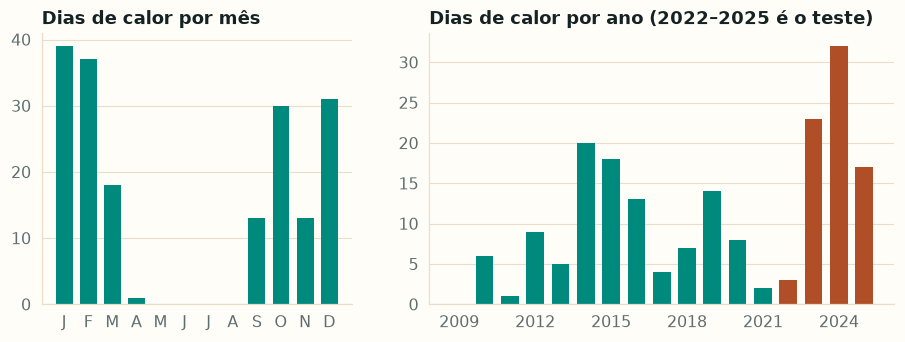

**Decisão: limiar de 32,22 °C (`CAUTELA_EXTREMA`).** Em 16 anos, o maior índice de calor medido na A701 foi **35,47 °C**: o nível `PERIGO` da tabela **nunca** ocorreu, e um alvo sem nenhum exemplo positivo não pode ser treinado. `ATENCAO` seria comum demais para ser um aviso. Com `CAUTELA_EXTREMA`, **2,5%** das amostras de treino são positivas: classes desbalanceadas, mas com exemplos reais. Para a pessoa idosa isso faz sentido: os limites pessoais do Sombra (R3) ficam abaixo da tabela geral, e o calor que a NWS chama de cautela extrema já é perigoso para quem tem 85 anos e cardiopatia.

In [6]:
perigosos = diario >= LIMIAR_ALVO_C
por_mes = perigosos.groupby(perigosos.index.month).sum()
por_ano = perigosos.groupby(perigosos.index.year).sum()
figura, (esq, dir_) = plt.subplots(1, 2, figsize=(10, 3.2), width_ratios=[1, 1.5])
esq.bar(por_mes.index, por_mes, color=fig.PERSISTENCIA, width=0.7)
esq.set_xticks(range(1, 13), list("JFMAMJJASOND"))
esq.set_title("Dias de calor por mês")
esq.grid(axis="x", visible=False)
dir_.bar(por_ano.index, por_ano, color=[fig.XGBOOST if a >= 2022 else fig.PERSISTENCIA for a in por_ano.index], width=0.7)
dir_.set_xticks(por_ano.index[::3])
dir_.set_title("Dias de calor por ano (2022–2025 é o teste)")
dir_.grid(axis="x", visible=False)
fig.salvar(figura, "02_dias_de_calor")
plt.show()
display(Markdown(
    f"**Decisão: limiar de {LIMIAR_ALVO_C:.2f} °C (`CAUTELA_EXTREMA`).** Em 16 anos, o maior índice de calor medido na A701 foi "
    f"**{base['indice_calor_c'].max():.2f} °C**: o nível `PERIGO` da tabela **nunca** ocorreu, e um alvo sem nenhum exemplo positivo não pode ser treinado. "
    f"`ATENCAO` seria comum demais para ser um aviso. Com `CAUTELA_EXTREMA`, **{(pico_treino >= LIMIAR_ALVO_C).mean():.1%}** das amostras de treino são positivas: "
    "classes desbalanceadas, mas com exemplos reais. Para a pessoa idosa isso faz sentido: os limites pessoais do Sombra (R3) ficam abaixo da tabela geral, "
    "e o calor que a NWS chama de cautela extrema já é perigoso para quem tem 85 anos e cardiopatia."
))

## 4. Features, sem olhar o futuro

Cada amostra enxerga **só a hora atual e as anteriores**, e só o que o Clima Service terá em produção: temperatura, umidade, pressão, radiação, vento e chuva das últimas 24 h. O ponto de orvalho é **calculado** (Magnus), porque o Clima Service não recebe essa medida em produção; a coluna medida pelo INMET serve apenas para conferir a fórmula.

Há uma amostra **a cada 6 h** (0h, 6h, 12h e 18h locais), o que reduz a autocorrelação entre linhas vizinhas.

In [7]:
grupos = pd.Series([f.agregacao if f.variavel != "tempo" else "ciclo (hora e dia do ano)" for f in CATALOGO]).value_counts()
erro_orvalho = (orvalho_c(limpa["temperatura_c"], limpa["umidade_pct"]) - limpa["orvalho_inmet_c"]).abs().mean()
display(Markdown(
    f"**{len(NOMES_DAS_FEATURES)} features** em {len(amostras)} amostras. O orvalho calculado erra, em média, **{erro_orvalho:.2f} °C** em relação ao medido."
))
grupos.rename("features").to_frame()

**63 features** em 23071 amostras. O orvalho calculado erra, em média, **0,07 °C** em relação ao medido.

,features
media,19
delta,16
maximo,8
soma,8
atual,6
ciclo (hora e dia do ano),4
minimo,1
amplitude,1


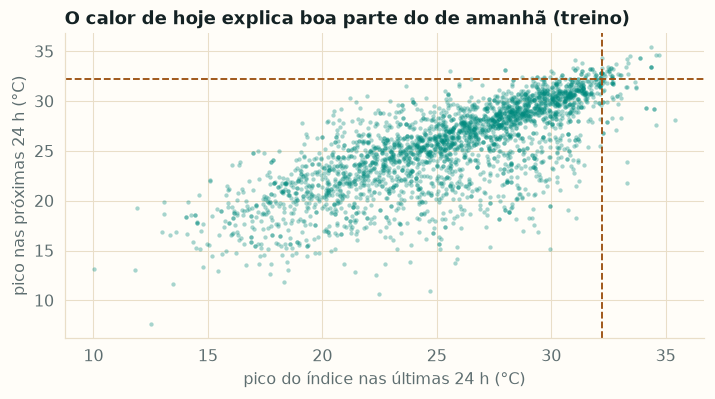

Correlação entre o pico passado e o futuro no treino: **0,75**. Por isso a persistência é um adversário forte, e vira o primeiro baseline.

In [8]:
figura, eixo = plt.subplots(figsize=(7.5, 3.6))
treino = amostras[ano_local <= 2021]
amostra = treino.sample(3000, random_state=42)
eixo.scatter(amostra["indice_calor_maximo_24h"], amostra["pico_futuro_c"], s=8, color=fig.PERSISTENCIA, alpha=0.35, linewidths=0)
eixo.axhline(LIMIAR_ALVO_C, color=fig.LIMIAR, linewidth=1.2, linestyle="--")
eixo.axvline(LIMIAR_ALVO_C, color=fig.LIMIAR, linewidth=1.2, linestyle="--")
eixo.set_xlabel("pico do índice nas últimas 24 h (°C)")
eixo.set_ylabel("pico nas próximas 24 h (°C)")
eixo.set_title("O calor de hoje explica boa parte do de amanhã (treino)")
fig.salvar(figura, "03_persistencia")
plt.show()
correlacao = treino["indice_calor_maximo_24h"].corr(treino["pico_futuro_c"])
display(Markdown(f"Correlação entre o pico passado e o futuro no treino: **{correlacao:.2f}**. Por isso a persistência é um adversário forte, e vira o primeiro baseline."))

## 5. Divisão temporal e baselines

Clima tem memória: embaralhar colocaria o dia seguinte de uma onda de calor no treino e o dia anterior no teste, e o resultado pareceria melhor do que é. Por isso:

- **Treino: 2010 a 2021. Teste: 2022 a 2025**, que inclui as ondas de calor recordes de 2023 e 2024, nunca vistas pelo modelo.
- As amostras das últimas 24 h de 2021 **saem do treino**, porque o alvo delas olharia para dentro do teste.
- A validação cruzada é só no treino, com `TimeSeriesSplit(5)` e **24 h de folga** entre ajuste e validação pelo mesmo motivo.

O teste fica guardado até a seção 8. Aqui, os baselines são comparados **só na validação temporal**.

In [9]:
from sombra_ml.modelagem import (
    dividir_temporal,
    limiar_para_recall,
    matriz,
    metricas,
    nova_logistica,
    probabilidades_fora_da_amostra,
    validacao_temporal,
)

RECALL_ALVO = 0.90
treino, teste = dividir_temporal(amostras)
X_treino, y_treino = matriz(treino), treino["alvo"].to_numpy()
X_teste, y_teste = matriz(teste), teste["alvo"].to_numpy()
pd.DataFrame(
    {
        "período": [f"{d.index.min():%d/%m/%Y} a {d.index.max():%d/%m/%Y}" for d in (treino, teste)],
        "amostras": [len(treino), len(teste)],
        "positivas": [int(y_treino.sum()), int(y_teste.sum())],
        "% positivas": [100 * y_treino.mean(), 100 * y_teste.mean()],
    },
    index=["treino", "teste"],
)

,período,amostras,positivas,% positivas
treino,01/01/2010 a 30/12/2021,17365,430,2.476
teste,01/01/2022 a 31/12/2025,5702,301,5.279


In [10]:
persistencia_treino = treino["indice_calor_maximo_24h"].to_numpy()
oof_logistica = probabilidades_fora_da_amostra(nova_logistica(), X_treino, y_treino)
validado = ~np.isnan(oof_logistica)
y_validacao = y_treino[validado]

limiar_logistica = limiar_para_recall(y_validacao, oof_logistica[validado], RECALL_ALVO)
limiar_persistencia = limiar_para_recall(y_validacao, persistencia_treino[validado], RECALL_ALVO)
baselines_validacao = pd.DataFrame(
    {
        "persistência: regra direta (pico de hoje ≥ 32,22 °C)": metricas(y_validacao, persistencia_treino[validado], LIMIAR_ALVO_C, probabilidade=False),
        "persistência: limiar para recall ≥ 0,90": metricas(y_validacao, persistencia_treino[validado], limiar_persistencia, probabilidade=False),
        "regressão logística: limiar para recall ≥ 0,90": metricas(y_validacao, oof_logistica[validado], limiar_logistica),
    }
).T
baselines_validacao

,precisao,recall,f1,f2,roc_auc,pr_auc,brier
"persistência: regra direta (pico de hoje ≥ 32,22 °C)",0.434,0.435,0.435,0.435,0.938,0.360,NaN
"persistência: limiar para recall ≥ 0,90",0.140,0.900,0.243,0.432,0.938,0.360,NaN
"regressão logística: limiar para recall ≥ 0,90",0.111,0.900,0.197,0.371,0.926,0.335,0.022


**Como ler.** A *persistência* diz que amanhã será igual a hoje: é o mesmo raciocínio do previsor por regra que o Clima Service usa quando o modelo não está disponível. Sua pontuação é o próprio índice de calor, em °C, e por isso não há Brier. A *regressão logística* mostra até onde vai um modelo linear com as mesmas features. O XGBoost só se justifica se superar esses dois.

## 6. Por que XGBoost, e o treino com diferentes parâmetros

O problema é tabular, com relações não lineares entre temperatura, umidade e radiação (o próprio índice de calor é um polinômio com interações). O XGBoost lida bem com isso, aceita valores ausentes sem imputação, treina rápido e **exporta para ONNX**, o que permite servir o modelo dentro do Clima Service em Java.

Com poucos positivos, ele decora o treino com facilidade. Antes da busca, comparamos níveis de regularização, sempre **na validação temporal do treino**.

In [11]:
from sklearn.model_selection import cross_val_score

from sombra_ml.modelagem import GRADE, REGULARIZACAO, buscar_hiperparametros, novo_xgboost, tabela_da_busca

candidatas = {
    "fraca (peso mínimo 1, 80% das colunas)": {"min_child_weight": 1, "colsample_bytree": 0.8},
    "média (peso mínimo 5, 80% das colunas)": {"min_child_weight": 5, "colsample_bytree": 0.8},
    "escolhida (peso mínimo 10, 60% das colunas)": {"min_child_weight": 10, "colsample_bytree": 0.6},
    "forte (peso mínimo 20, 50% das colunas, L2 = 10)": {"min_child_weight": 20, "colsample_bytree": 0.5, "reg_lambda": 10},
}
linhas = []
for nome, ajuste in candidatas.items():
    notas = cross_val_score(
        novo_xgboost(max_depth=3, learning_rate=0.03, n_estimators=200, **ajuste),
        X_treino, y_treino, scoring="average_precision", cv=validacao_temporal(),
    )
    linhas.append({"regularização": nome, "PR-AUC (validação)": notas.mean(), "desvio": notas.std()})
pd.DataFrame(linhas)

,regularização,PR-AUC (validação),desvio
0,"fraca (peso mínimo 1, 80% das colunas)",0.288,0.068
1,"média (peso mínimo 5, 80% das colunas)",0.316,0.038
2,"escolhida (peso mínimo 10, 60% das colunas)",0.332,0.065
3,"forte (peso mínimo 20, 50% das colunas, L2 = 10)",0.270,0.126


Agora a busca pedida: **3 hiperparâmetros, 12 combinações** (`max_depth` × `learning_rate` × `n_estimators`), com `GridSearchCV`, `TimeSeriesSplit(5)` e `average_precision` como critério, porque a acurácia não diz nada com tão poucos positivos.

In [12]:
busca = buscar_hiperparametros(X_treino, y_treino)
tabela_busca = tabela_da_busca(busca)
modelo = busca.best_estimator_
(RAIZ / "modelo").mkdir(exist_ok=True)
tabela_busca.to_csv(RAIZ / "modelo" / "busca_hiperparametros.csv", index=False, float_format="%.5f")
tabela_busca

,max_depth,learning_rate,n_estimators,pr_auc_validacao,desvio_validacao,pr_auc_treino,diferenca
0,3,0.030,200,0.332,0.065,0.728,0.397
1,5,0.030,200,0.321,0.056,0.790,0.470
2,7,0.030,200,0.314,0.051,0.821,0.507
3,3,0.030,500,0.310,0.040,0.837,0.527
4,5,0.100,500,0.306,0.037,0.956,0.650
5,5,0.100,200,0.306,0.031,0.936,0.630
6,3,0.100,200,0.304,0.019,0.874,0.570
7,5,0.030,500,0.300,0.036,0.907,0.608
8,7,0.030,500,0.298,0.032,0.923,0.625
9,7,0.100,200,0.297,0.020,0.941,0.644


In [13]:
display(Markdown(
    f"**Melhor combinação:** `max_depth={busca.best_params_['max_depth']}`, `learning_rate={busca.best_params_['learning_rate']}`, "
    f"`n_estimators={busca.best_params_['n_estimators']}`, com PR-AUC de **{busca.best_score_:.3f}** na validação "
    f"(desvio de {tabela_busca.loc[0, 'desvio_validacao']:.3f} entre as dobras). A coluna `diferenca` mostra quanto o desempenho cai do treino para a validação: "
    "ela cresce com a profundidade e com o número de árvores, e é o primeiro sinal de overfitting."
))

**Melhor combinação:** `max_depth=3`, `learning_rate=0,03`, `n_estimators=200`, com PR-AUC de **0,332** na validação (desvio de 0,065 entre as dobras). A coluna `diferenca` mostra quanto o desempenho cai do treino para a validação: ela cresce com a profundidade e com o número de árvores, e é o primeiro sinal de overfitting.

## 7. O limiar de decisão, escolhido sem tocar no teste

Uma probabilidade só vira aviso depois de um limiar. Ele é escolhido nas **previsões fora da amostra do treino**: o maior valor que ainda alcança **recall ≥ 0,90**. Depois é aplicado **uma única vez** no teste. Também registramos dois pontos menos sensíveis, porque cada recall a mais custa alarmes para a família.

In [14]:
from sombra_ml.avaliacao import avaliar_avisos, curva_de_aprendizado, diferenca_pr_auc_por_blocos

oof_xgboost = probabilidades_fora_da_amostra(novo_xgboost(**busca.best_params_), X_treino, y_treino)
limiares = {r: limiar_para_recall(y_validacao, oof_xgboost[validado], r) for r in (0.90, 0.80, 0.70)}
limiar = limiares[RECALL_ALVO]
pd.DataFrame(
    {f"recall ≥ {r:.2f}": {"limiar": v, **metricas(y_validacao, oof_xgboost[validado], v)} for r, v in limiares.items()}
).T[["limiar", "precisao", "recall", "f1", "f2"]]

,limiar,precisao,recall,f1,f2
recall ≥ 0.90,0.010,0.119,0.900,0.210,0.389
recall ≥ 0.80,0.023,0.166,0.801,0.275,0.454
recall ≥ 0.70,0.037,0.202,0.701,0.314,0.470


## 8. Resultados em treino e teste, lado a lado

In [15]:
logistica = nova_logistica().fit(X_treino, y_treino)
prob_treino = modelo.predict_proba(X_treino)[:, 1]
prob_teste = modelo.predict_proba(X_teste)[:, 1]
prob_logistica_teste = logistica.predict_proba(X_teste)[:, 1]
persistencia_teste = teste["indice_calor_maximo_24h"].to_numpy()

resultado_xgboost = pd.DataFrame(
    {
        "treino (dados já vistos)": metricas(y_treino, prob_treino, limiar),
        "validação temporal": metricas(y_validacao, oof_xgboost[validado], limiar),
        "teste 2022–2025": metricas(y_teste, prob_teste, limiar),
    }
)
resultado_xgboost

,treino (dados já vistos),validação temporal,teste 2022–2025
precisao,0.114,0.119,0.208
recall,1.000,0.900,0.970
f1,0.205,0.210,0.342
f2,0.392,0.389,0.559
roc_auc,0.980,0.921,0.960
pr_auc,0.658,0.292,0.588
brier,0.014,0.023,0.034


In [16]:
comparacao_teste = pd.DataFrame(
    {
        "persistência · regra direta": metricas(y_teste, persistencia_teste, LIMIAR_ALVO_C, probabilidade=False),
        "persistência · recall 0,90 no treino": metricas(y_teste, persistencia_teste, limiar_persistencia, probabilidade=False),
        "regressão logística": metricas(y_teste, prob_logistica_teste, limiar_logistica),
        "XGBoost": metricas(y_teste, prob_teste, limiar),
    }
).T
meses_teste = teste.index.tz_convert(FUSO_LOCAL).strftime("%Y-%m").to_numpy()
contra_persistencia = diferenca_pr_auc_por_blocos(y_teste, prob_teste, persistencia_teste, meses_teste)
contra_logistica = diferenca_pr_auc_por_blocos(y_teste, prob_teste, prob_logistica_teste, meses_teste)
display(comparacao_teste)
display(Markdown(
    f"**PR-AUC do XGBoost menos a da persistência:** {contra_persistencia['diferenca']:+.3f} "
    f"(IC 95% por blocos mensais: {contra_persistencia['ic95_inferior']:+.3f} a {contra_persistencia['ic95_superior']:+.3f}). "
    f"**Menos a da logística:** {contra_logistica['diferenca']:+.3f} "
    f"({contra_logistica['ic95_inferior']:+.3f} a {contra_logistica['ic95_superior']:+.3f}). "
    "Se o intervalo contém zero, os dados de teste não bastam para afirmar que um é melhor que o outro."
))

,precisao,recall,f1,f2,roc_auc,pr_auc,brier
persistência · regra direta,0.583,0.571,0.577,0.574,0.952,0.575,NaN
"persistência · recall 0,90 no treino",0.225,0.944,0.363,0.575,0.952,0.575,NaN
regressão logística,0.179,0.980,0.303,0.517,0.958,0.582,0.034
XGBoost,0.208,0.970,0.342,0.559,0.960,0.588,0.034


**PR-AUC do XGBoost menos a da persistência:** +0,013 (IC 95% por blocos mensais: -0,099 a +0,114). **Menos a da logística:** +0,006 (-0,061 a +0,102). Se o intervalo contém zero, os dados de teste não bastam para afirmar que um é melhor que o outro.

In [17]:
indice_teste = base["indice_calor_c"].loc[teste.index.min():teste.index.max()]
alvo_teste = teste["alvo"]
def avisos(pontuacao, corte):
    return avaliar_avisos(pd.Series(pontuacao, index=teste.index), alvo_teste, corte, indice_teste)

avisos_teste = pd.DataFrame(
    {
        "persistência · regra direta": avisos(persistencia_teste, LIMIAR_ALVO_C),
        "persistência · recall 0,90": avisos(persistencia_teste, limiar_persistencia),
        "regressão logística · recall 0,90": avisos(prob_logistica_teste, limiar_logistica),
        "XGBoost · recall 0,90": avisos(prob_teste, limiares[0.90]),
        "XGBoost · recall 0,80": avisos(prob_teste, limiares[0.80]),
        "XGBoost · recall 0,70": avisos(prob_teste, limiares[0.70]),
    }
).T
avisos_teste

,dias_de_calor,dias_avisados,taxa_de_aviso,antecedencia_mediana_h,dias_com_alarme,dias_com_alarme_falso,alarmes_falsos_por_mes
persistência · regra direta,75.000,43.000,0.573,21.000,106.000,44.000,0.917
"persistência · recall 0,90",75.000,74.000,0.987,21.000,418.000,316.000,6.588
"regressão logística · recall 0,90",75.000,75.000,1.000,21.000,560.000,454.000,9.466
"XGBoost · recall 0,90",75.000,74.000,0.987,21.000,480.000,376.000,7.839
"XGBoost · recall 0,80",75.000,72.000,0.960,21.000,335.000,236.000,4.920
"XGBoost · recall 0,70",75.000,71.000,0.947,21.000,269.000,176.000,3.669


**Leitura honesta.** No teste, o XGBoost, a regressão logística e a persistência ficam praticamente empatados na ordenação dos casos: as diferenças de PR-AUC cabem no intervalo de incerteza. O pico de calor das últimas 24 h já carrega quase toda a informação disponível numa única estação. Com o limiar para recall alto, o sistema avisa quase todos os dias de calor, mas paga com muitos dias de alarme falso. É por isso que a tabela mostra também os pontos de recall 0,80 e 0,70: a escolha é um compromisso, não um detalhe técnico.

In [18]:
ano_teste = teste.index.tz_convert(FUSO_LOCAL).year
por_ano_teste = pd.DataFrame(
    {
        ano: {"positivas": int(y_teste[ano_teste == ano].sum()), **metricas(y_teste[ano_teste == ano], prob_teste[ano_teste == ano], limiar)}
        for ano in sorted(set(ano_teste))
    }
).T[["positivas", "precisao", "recall", "pr_auc"]]
por_ano_teste

,positivas,precisao,recall,pr_auc
2022,12.000,0.049,1.000,0.113
2023,94.000,0.232,0.979,0.717
2024,126.000,0.284,0.944,0.638
2025,69.000,0.201,1.000,0.533


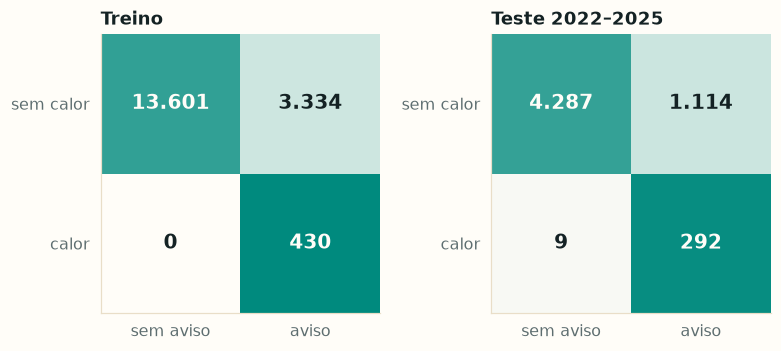

In [19]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_curve
from matplotlib.colors import LinearSegmentedColormap

mapa = LinearSegmentedColormap.from_list("sombra", [fig.FUNDO, fig.PERSISTENCIA])
figura, eixos = plt.subplots(1, 2, figsize=(8.4, 3.3))
for eixo, titulo, y, p in [(eixos[0], "Treino", y_treino, prob_treino), (eixos[1], "Teste 2022–2025", y_teste, prob_teste)]:
    matriz_confusao = confusion_matrix(y, p >= limiar)
    eixo.imshow(matriz_confusao / matriz_confusao.sum(axis=1, keepdims=True), cmap=mapa, vmin=0, vmax=1)
    for (linha, coluna), valor in np.ndenumerate(matriz_confusao):
        claro = matriz_confusao[linha, coluna] / matriz_confusao[linha].sum() > 0.6
        eixo.text(coluna, linha, f"{valor:,}".replace(",", "."), ha="center", va="center", fontsize=13, fontweight="bold", color=fig.FUNDO if claro else fig.TINTA)
    eixo.set_xticks([0, 1], ["sem aviso", "aviso"])
    eixo.set_yticks([0, 1], ["sem calor", "calor"])
    eixo.grid(False)
    eixo.set_title(titulo)
fig.salvar(figura, "04_matrizes_de_confusao")
plt.show()

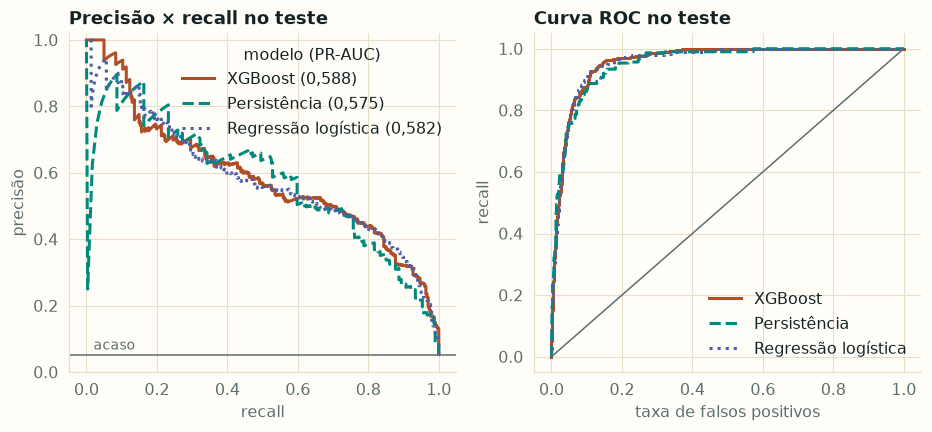

In [20]:
series = [
    ("XGBoost", prob_teste, fig.XGBOOST, "-"),
    ("Persistência", persistencia_teste, fig.PERSISTENCIA, "--"),
    ("Regressão logística", prob_logistica_teste, fig.LOGISTICA, ":"),
]
figura, (pr, roc) = plt.subplots(1, 2, figsize=(10, 4))
for nome, pontuacao, cor, traco in series:
    precisao, recall, _ = precision_recall_curve(y_teste, pontuacao)
    pr.plot(recall, precisao, color=cor, linestyle=traco, label=f"{nome} ({average_precision_score(y_teste, pontuacao):.3f})".replace(".", ","))
    falso, verdadeiro, _ = roc_curve(y_teste, pontuacao)
    roc.plot(falso, verdadeiro, color=cor, linestyle=traco, label=nome)
pr.axhline(y_teste.mean(), color=fig.TINTA_SUAVE, linewidth=1, linestyle="-")
pr.text(0.02, y_teste.mean() + 0.015, "acaso", color=fig.TINTA_SUAVE, fontsize=9)
pr.set(xlabel="recall", ylabel="precisão", title="Precisão × recall no teste", ylim=(0, 1.02))
pr.legend(title="modelo (PR-AUC)", loc="upper right")
roc.plot([0, 1], [0, 1], color=fig.TINTA_SUAVE, linewidth=1)
roc.set(xlabel="taxa de falsos positivos", ylabel="recall", title="Curva ROC no teste")
roc.legend(loc="lower right")
fig.salvar(figura, "05_curvas_pr_roc")
plt.show()

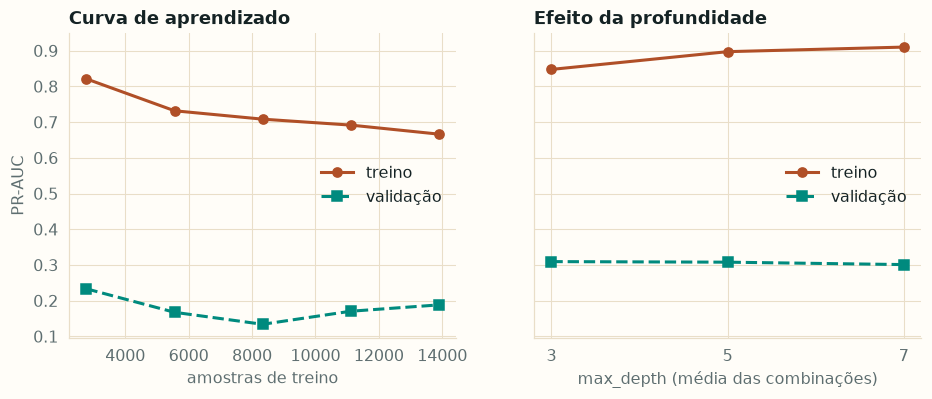

In [21]:
curva = curva_de_aprendizado(novo_xgboost(**busca.best_params_), X_treino, y_treino)
por_profundidade = tabela_busca.groupby("max_depth")[["pr_auc_treino", "pr_auc_validacao"]].mean()
figura, (aprendizado, profundidade) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for eixo, x, dados, rotulo_x in [
    (aprendizado, curva["amostras_de_treino"], curva, "amostras de treino"),
    (profundidade, por_profundidade.index, por_profundidade, "max_depth (média das combinações)"),
]:
    eixo.plot(x, dados["pr_auc_treino"], color=fig.XGBOOST, marker="o", label="treino")
    eixo.plot(x, dados["pr_auc_validacao"], color=fig.PERSISTENCIA, marker="s", linestyle="--", label="validação")
    eixo.set_xlabel(rotulo_x)
    eixo.legend(loc="center right")
profundidade.set_xticks(list(por_profundidade.index))
aprendizado.set_ylabel("PR-AUC")
aprendizado.set_title("Curva de aprendizado")
profundidade.set_title("Efeito da profundidade")
fig.salvar(figura, "06_overfitting")
plt.show()

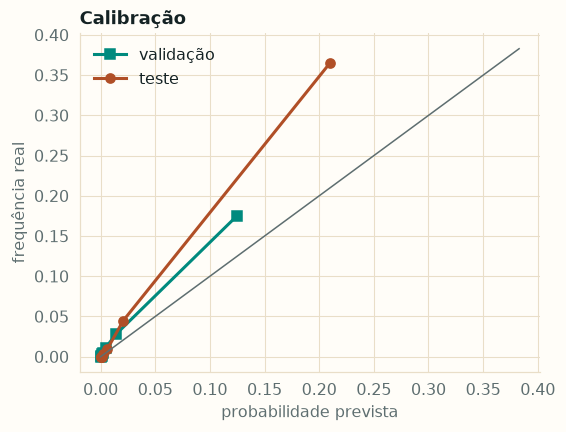

In [22]:
figura, eixo = plt.subplots(figsize=(5.4, 4))
for nome, y, p, cor, marca in [("validação", y_validacao, oof_xgboost[validado], fig.PERSISTENCIA, "s"), ("teste", y_teste, prob_teste, fig.XGBOOST, "o")]:
    real, previsto = calibration_curve(y, p, n_bins=8, strategy="quantile")
    eixo.plot(previsto, real, color=cor, marker=marca, label=nome)
limite = max(eixo.get_xlim()[1], eixo.get_ylim()[1])
eixo.plot([0, limite], [0, limite], color=fig.TINTA_SUAVE, linewidth=1)
eixo.set(xlabel="probabilidade prevista", ylabel="frequência real", title="Calibração")
eixo.legend()
fig.salvar(figura, "07_calibracao")
plt.show()

**Overfitting.** A PR-AUC no treino fica bem acima da validação temporal, mesmo com a árvore mais rasa da grade, e aumentar `max_depth` eleva o treino sem melhorar a validação: mais complexidade só decora. Por isso a busca escolheu o modelo mais simples. A PR-AUC do teste é maior que a da validação porque 2022–2025 têm mais do que o dobro de positivos, e essa métrica sobe com a frequência da classe; não é sinal de que o modelo melhorou. Na calibração, as probabilidades ficam abaixo da frequência real no teste: o clima recente está mais quente que o do treino, então a probabilidade deve ser lida como um indicador conservador de risco.

## 9. O que faz o modelo soar o alarme (SHAP)

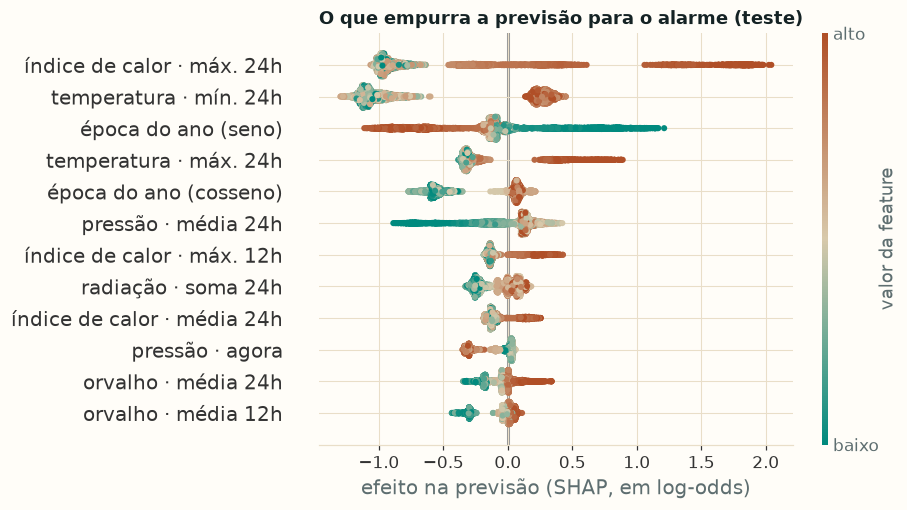

,|SHAP| médio
índice de calor · máx. 24h,0.838
temperatura · mín. 24h,0.735
época do ano (seno),0.344
temperatura · máx. 24h,0.322
época do ano (cosseno),0.312
pressão · média 24h,0.179
índice de calor · máx. 12h,0.149
radiação · soma 24h,0.130
índice de calor · média 24h,0.122
pressão · agora,0.115


In [23]:
import shap

def rotulo(nome):
    trocas = [("indice_calor", "índice de calor"), ("temperatura", "temperatura"), ("umidade", "umidade"), ("orvalho", "orvalho"), ("pressao", "pressão"), ("radiacao", "radiação"), ("vento", "vento"), ("chuva", "chuva"),
              ("_maximo_", " · máx. "), ("_media_", " · média "), ("_minimo_", " · mín. "), ("_soma_", " · soma "), ("_delta_", " · variação em "), ("_amplitude_", " · amplitude "), ("_atual", " · agora"),
              ("dia_do_ano_sen", "época do ano (seno)"), ("dia_do_ano_cos", "época do ano (cosseno)"), ("hora_sen", "hora do dia (seno)"), ("hora_cos", "hora do dia (cosseno)")]
    for de, para in trocas:
        nome = nome.replace(de, para)
    return nome

nomes_legiveis = [rotulo(n) for n in NOMES_DAS_FEATURES]
valores_shap = shap.TreeExplainer(modelo).shap_values(X_teste)
shap.summary_plot(valores_shap, X_teste, feature_names=nomes_legiveis, max_display=12, cmap=LinearSegmentedColormap.from_list("calor", [fig.PERSISTENCIA, "#D8C9AB", fig.XGBOOST]), show=False, plot_size=(8.5, 4.6))
figura = plt.gcf()
figura.axes[0].set_title("O que empurra a previsão para o alarme (teste)")
figura.axes[0].set_xlabel("efeito na previsão (SHAP, em log-odds)")
figura.axes[1].set_yticklabels(["baixo", "alto"])
figura.axes[1].set_ylabel("valor da feature")
fig.salvar(figura, "08_shap")
plt.show()
importancia = pd.Series(np.abs(valores_shap).mean(axis=0), index=nomes_legiveis).sort_values(ascending=False)
importancia.head(10).rename("|SHAP| médio").to_frame()

O modelo aprendeu o que um meteorologista esperaria: o **pico recente do índice de calor** e **noites que não esfriam** (mínima alta nas últimas 24 h) puxam o alarme, a **época do ano** define quando o risco é plausível, e a **pressão** baixa, típica da chegada de frentes, reduz o risco.

## 10. O pico previsto, em graus

O Core compara o pico previsto com o **limite pessoal** de cada morador (decisão D19): 85 anos com cardiopatia é perigo a partir de 34,94 °C, enquanto 78 anos com diurético só a partir de 37,94 °C. Uma probabilidade não responde a isso. Por isso há um segundo XGBoost, que prevê a **mediana do pico das próximas 24 h**, e uma **margem** medida na validação temporal, para quem prefere errar para o lado seguro.

In [24]:
from sombra_ml.modelagem import margem_superior, novo_regressor_pico, previsoes_fora_da_amostra

pico_treino_real = treino["pico_futuro_c"].to_numpy()
pico_teste_real = teste["pico_futuro_c"].to_numpy()
oof_pico = previsoes_fora_da_amostra(novo_regressor_pico(), X_treino, pico_treino_real)
validado_pico = ~np.isnan(oof_pico)
margem_p90 = margem_superior(pico_treino_real[validado_pico], oof_pico[validado_pico])
regressor = novo_regressor_pico().fit(X_treino, pico_treino_real)
pico_teste = regressor.predict(X_teste).astype(float)

def resumo_pico(real, previsto):
    erro = previsto - real
    return {"erro absoluto médio (°C)": np.abs(erro).mean(), "viés (°C)": erro.mean(), "% dos picos cobertos": 100 * (real <= previsto).mean()}

calor = teste["alvo"].to_numpy() == 1
tabela_pico = pd.DataFrame(
    {
        "persistência (pico de hoje)": resumo_pico(pico_teste_real, persistencia_teste),
        "XGBoost, mediana": resumo_pico(pico_teste_real, pico_teste),
        "XGBoost, mediana + margem": resumo_pico(pico_teste_real, pico_teste + margem_p90),
        "só dias de calor · persistência": resumo_pico(pico_teste_real[calor], persistencia_teste[calor]),
        "só dias de calor · XGBoost, mediana": resumo_pico(pico_teste_real[calor], pico_teste[calor]),
        "só dias de calor · mediana + margem": resumo_pico(pico_teste_real[calor], pico_teste[calor] + margem_p90),
    }
).T
display(Markdown(f"Margem medida na validação temporal do treino: **+{margem_p90:.2f} °C**."))
tabela_pico

Margem medida na validação temporal do treino: **+2,30 °C**.

,erro absoluto médio (°C),viés (°C),% dos picos cobertos
persistência (pico de hoje),2.207,-0.011,43.406
"XGBoost, mediana",1.648,-0.071,43.722
"XGBoost, mediana + margem",2.533,2.232,87.864
só dias de calor · persistência,1.245,-0.892,21.262
"só dias de calor · XGBoost, mediana",2.190,-2.190,0.332
só dias de calor · mediana + margem,0.970,0.113,60.797


**Atenção ao usar a mediana.** Ela é a melhor estimativa em geral, com erro menor que o da persistência, mas nos dias de calor fica sistematicamente abaixo do pico real: os extremos são raros e o modelo puxa para o centro. Para decidir sobre uma pessoa vulnerável, a mediana sozinha é otimista; a margem existe por isso.

## 11. Replay da onda de calor de novembro de 2023

O que o modelo teria dito, hora a hora, usando só o que já tinha sido medido em cada momento. Esse período está no teste: o modelo nunca o viu.

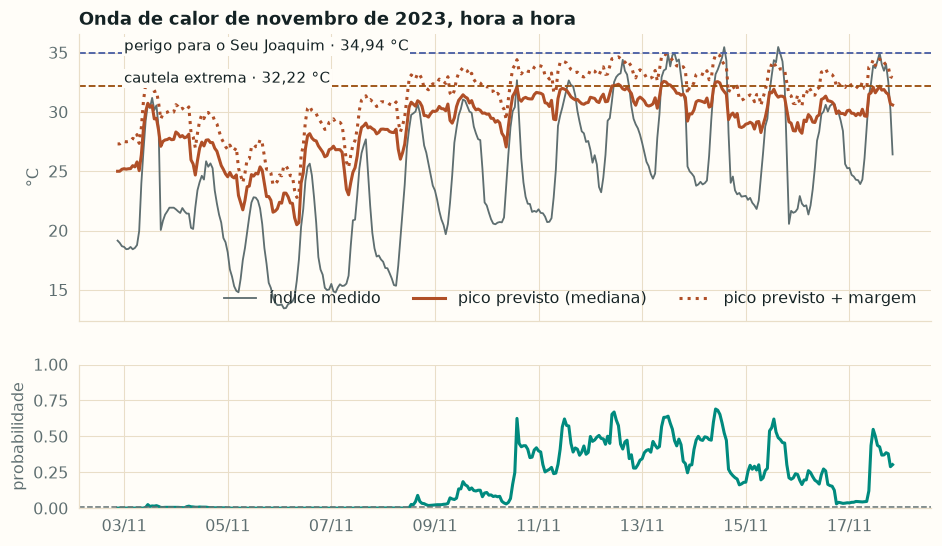

- Primeira hora medida em cautela extrema: **10/11 às 14h**; a probabilidade passou de 25% em **10/11 às 14h**. O limiar de decisão (0,010) é tão sensível que o alarme já aparecia dias antes: é o preço do recall alto.
- Maior índice medido: **35,47 °C**; maior pico previsto: **32,58 °C** (com a margem, 34,88 °C).
- Limite do Seu Joaquim alcançado pela mediana: **nunca, neste período**; pela mediana + margem: **nunca, neste período**.

In [25]:
import matplotlib.dates as mdates

from sombra_ml.features import calcular_features

LIMITE_SEU_JOAQUIM_C = 34.94
periodo = limpa.loc["2023-11-03":"2023-11-17"]
horas = periodo.index[periodo["observada"]]
X_replay = calcular_features(limpa).loc[horas, NOMES_DAS_FEATURES].to_numpy(dtype=np.float32)
replay = pd.DataFrame(
    {"probabilidade": modelo.predict_proba(X_replay)[:, 1], "pico": regressor.predict(X_replay).astype(float), "medido": base["indice_calor_c"].loc[horas]},
    index=horas.tz_convert(FUSO_LOCAL),
)
replay["pico_com_margem"] = replay["pico"] + margem_p90
figura, (alto, baixo) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, height_ratios=[2, 1])
alto.plot(replay.index, replay["medido"], color=fig.TINTA_SUAVE, linewidth=1.2, label="índice medido")
alto.plot(replay.index, replay["pico"], color=fig.XGBOOST, label="pico previsto (mediana)")
alto.plot(replay.index, replay["pico_com_margem"], color=fig.XGBOOST, linestyle=":", label="pico previsto + margem")
alto.axhline(LIMITE_SEU_JOAQUIM_C, color=fig.LOGISTICA, linewidth=1.2, linestyle="--")
alto.text(replay.index[3], LIMITE_SEU_JOAQUIM_C + 0.25, "perigo para o Seu Joaquim · 34,94 °C", fontsize=9.5, bbox={"facecolor": fig.FUNDO, "edgecolor": "none", "pad": 1.5})
alto.axhline(LIMIAR_ALVO_C, color=fig.LIMIAR, linewidth=1.2, linestyle="--")
alto.text(replay.index[3], LIMIAR_ALVO_C + 0.25, "cautela extrema · 32,22 °C", fontsize=9.5, bbox={"facecolor": fig.FUNDO, "edgecolor": "none", "pad": 1.5})
alto.set_ylabel("°C")
alto.set_title("Onda de calor de novembro de 2023, hora a hora")
alto.legend(loc="lower right", ncols=3)
baixo.plot(replay.index, replay["probabilidade"], color=fig.PERSISTENCIA)
baixo.axhline(limiar, color=fig.TINTA_SUAVE, linewidth=1, linestyle="--")
baixo.set_ylabel("probabilidade")
baixo.set_ylim(0, 1)
baixo.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m", tz=replay.index.tz))
fig.salvar(figura, "09_replay_nov_2023")
plt.show()

def primeira(condicao):
    momentos = replay.index[condicao]
    return f"{momentos[0]:%d/%m às %Hh}" if len(momentos) else "nunca, neste período"

primeiro_calor = replay.index[replay["medido"] >= LIMIAR_ALVO_C][0]
display(Markdown(
    f"- Primeira hora medida em cautela extrema: **{primeiro_calor:%d/%m às %Hh}**; a probabilidade passou de 25% em **{primeira(replay['probabilidade'] >= 0.25)}**. O limiar de decisão ({limiar:.3f}) é tão sensível que o alarme já aparecia dias antes: é o preço do recall alto.\n"
    f"- Maior índice medido: **{replay['medido'].max():.2f} °C**; maior pico previsto: **{replay['pico'].max():.2f} °C** (com a margem, {replay['pico_com_margem'].max():.2f} °C).\n"
    f"- Limite do Seu Joaquim alcançado pela mediana: **{primeira(replay['pico'] >= LIMITE_SEU_JOAQUIM_C)}**; pela mediana + margem: **{primeira(replay['pico_com_margem'] >= LIMITE_SEU_JOAQUIM_C)}**."
))

**Consequência para a integração (F9.1).** Hoje, o preventivo da demonstração abre na casa do Seu Joaquim porque a regra de persistência repete o pico já medido (35,47 °C). O modelo, sozinho, fica abaixo do limite dele nesse episódio, mesmo com a margem. Se o ONNX substituir a regra sem mais nada, o preventivo deixa de abrir. A saída mais segura é usar, como pico previsto, o **maior valor entre a persistência e a mediana + margem**, nunca menos do que já foi medido.

## 12. Exportação para produção

O Clima Service em Java carrega os modelos em **ONNX**. O `features.json` descreve cada feature; `paridade.csv` traz 20 amostras com a saída do Python; `paridade-janelas.json` traz as observações brutas dessas amostras, para testar também o cálculo das features em Java (F9.1).

In [26]:
import json

from sombra_ml.exportacao import ARQUIVO_CLASSIFICADOR, ARQUIVO_REGRESSOR, especificacao, exportar_onnx, prever_onnx, selecionar_paridade
from sombra_ml.features import features_da_janela

PASTA_MODELO = RAIZ / "modelo"
arquivo_prob = exportar_onnx(modelo, PASTA_MODELO / ARQUIVO_CLASSIFICADOR)
arquivo_pico = exportar_onnx(regressor, PASTA_MODELO / ARQUIVO_REGRESSOR)
(PASTA_MODELO / "features.json").write_text(
    json.dumps(especificacao(limiar, margem_p90, {f"{r:.2f}": v for r, v in limiares.items()}), ensure_ascii=False, indent=2) + "\n", "utf-8"
)

momentos = selecionar_paridade(teste)
X_paridade = matriz(teste.loc[momentos])
paridade = teste.loc[momentos, NOMES_DAS_FEATURES].copy()
paridade.insert(0, "instante_utc", momentos.strftime("%Y-%m-%dT%H:%M:%SZ"))
paridade["alvo"] = teste.loc[momentos, "alvo"]
paridade["probabilidade_python"] = modelo.predict_proba(X_paridade)[:, 1].astype(float)
paridade["pico_python_c"] = regressor.predict(X_paridade).astype(float)
paridade.to_csv(PASTA_MODELO / "paridade.csv", index=False)

COLUNAS_DA_JANELA = ["temperatura_c", "umidade_pct", "pressao_hpa", "radiacao_kj_m2", "vento_ms", "chuva_mm"]
casos = []
for momento in momentos:
    janela = limpa.loc[momento - pd.Timedelta(hours=23):momento, COLUNAS_DA_JANELA].dropna(subset=["temperatura_c", "umidade_pct"])
    calculadas = features_da_janela(janela)
    np.testing.assert_allclose(calculadas.to_numpy(float), teste.loc[momento, NOMES_DAS_FEATURES].to_numpy(float), rtol=1e-9, atol=1e-9)
    observacoes = [
        {"instante": f"{i:%Y-%m-%dT%H:%M:%SZ}", **{c: (None if pd.isna(v) else float(v)) for c, v in linha.items()}}
        for i, linha in janela.iterrows()
    ]
    casos.append({
        "instante": f"{momento:%Y-%m-%dT%H:%M:%SZ}",
        "observacoes": observacoes,
        "features": {n: (None if pd.isna(v) else float(v)) for n, v in calculadas.items()},
        "probabilidade": float(paridade.loc[momento, "probabilidade_python"]),
        "picoC": float(paridade.loc[momento, "pico_python_c"]),
    })
(PASTA_MODELO / "paridade-janelas.json").write_text(json.dumps({"casos": casos}, ensure_ascii=False, allow_nan=False) + "\n", "utf-8")

desvio_paridade = np.abs(prever_onnx(arquivo_prob, X_paridade) - paridade["probabilidade_python"]).max()
desvio_teste_prob = np.abs(prever_onnx(arquivo_prob, X_teste) - prob_teste).max()
desvio_teste_pico = np.abs(prever_onnx(arquivo_pico, X_teste) - pico_teste).max()
assert desvio_paridade < 1e-5 and desvio_teste_prob < 1e-5
display(Markdown(
    f"Paridade ONNX × XGBoost: maior diferença de **{desvio_paridade:.1e}** nas 20 amostras e **{desvio_teste_prob:.1e}** em todo o teste "
    f"({len(X_teste)} linhas). No pico, **{desvio_teste_pico:.1e} °C**."
))

Paridade ONNX × XGBoost: maior diferença de **4,8e-07** nas 20 amostras e **3,4e-07** em todo o teste (5702 linhas). No pico, **4,0e-05 °C**.

In [27]:
principal = avisos_teste.loc["XGBoost · recall 0,90"]
moderado = avisos_teste.loc["XGBoost · recall 0,70"]
metricas_publicadas = {
    "periodoTeste": "2022-2025",
    "melhoresHiperparametros": busca.best_params_,
    "limiarDeDecisao": limiar,
    "margemSuperiorP90C": margem_p90,
    "xgboost": resultado_xgboost.to_dict(),
    "comparacaoNoTeste": comparacao_teste.replace({np.nan: None}).to_dict("index"),
    "contraPersistencia": contra_persistencia,
    "contraLogistica": contra_logistica,
    "avisos": avisos_teste.replace({np.nan: None}).to_dict("index"),
    "picoNoTeste": tabela_pico.to_dict("index"),
}
(PASTA_MODELO / "metricas.json").write_text(json.dumps(metricas_publicadas, ensure_ascii=False, indent=2, default=float) + "\n", "utf-8")
display(Markdown(
    "## 13. Conclusão para o cidadão\n\n"
    f"> **Entre 2022 e 2025, de cada 10 dias de calor forte em São Paulo, o Sombra teria avisado a família de {10 * principal['taxa_de_aviso']:.1f} "
    f"com até 24 horas de antecedência, ao custo de {principal['alarmes_falsos_por_mes']:.1f} dias com alarme falso por mês.**\n\n"
    f"Esse custo é alto para uma família que pediu pouco barulho. Com um limiar menos sensível, o aviso ainda chega em {10 * moderado['taxa_de_aviso']:.1f} de cada 10 dias, "
    f"com {moderado['alarmes_falsos_por_mes']:.1f} dias de alarme falso por mês. Por isso a probabilidade não deve disparar sozinha um alerta para a rede: "
    "no Sombra, o preventivo depende do pico previsto e do limite pessoal de quem mora na casa, e o escalonamento começa com um lembrete leve.\n\n"
    "### O que o modelo não prova\n\n"
    f"- **O XGBoost não superou a persistência com folga estatística** (diferença de PR-AUC de {contra_persistencia['diferenca']:+.3f}, IC 95% de {contra_persistencia['ic95_inferior']:+.3f} a {contra_persistencia['ic95_superior']:+.3f}). A regra simples continua sendo um bom plano B.\n"
    "- **Uma estação não é uma casa.** O Mirante de Santana mede o ar externo, em abrigo meteorológico; dentro de uma casa fechada pode fazer mais calor. É o papel da Sentinela.\n"
    "- **O nível `PERIGO` da NWS nunca ocorreu na série**, então o modelo prevê `CAUTELA_EXTREMA`, e não perigo clínico.\n"
    "- **Treino com INMET, produção com Open-Meteo.** A previsão ao vivo usa outra fonte, com possíveis diferenças de medição que este teste não mede.\n"
    "- **O clima está mudando:** o teste tem o dobro de dias quentes do treino, e as probabilidades ficaram subestimadas.\n"
    "- O Sombra **não é um dispositivo médico** e não substitui o SAMU nem a Defesa Civil."
))

## 13. Conclusão para o cidadão

> **Entre 2022 e 2025, de cada 10 dias de calor forte em São Paulo, o Sombra teria avisado a família de 9,9 com até 24 horas de antecedência, ao custo de 7,8 dias com alarme falso por mês.**

Esse custo é alto para uma família que pediu pouco barulho. Com um limiar menos sensível, o aviso ainda chega em 9,5 de cada 10 dias, com 3,7 dias de alarme falso por mês. Por isso a probabilidade não deve disparar sozinha um alerta para a rede: no Sombra, o preventivo depende do pico previsto e do limite pessoal de quem mora na casa, e o escalonamento começa com um lembrete leve.

### O que o modelo não prova

- **O XGBoost não superou a persistência com folga estatística** (diferença de PR-AUC de +0,013, IC 95% de -0,099 a +0,114). A regra simples continua sendo um bom plano B.
- **Uma estação não é uma casa.** O Mirante de Santana mede o ar externo, em abrigo meteorológico; dentro de uma casa fechada pode fazer mais calor. É o papel da Sentinela.
- **O nível `PERIGO` da NWS nunca ocorreu na série**, então o modelo prevê `CAUTELA_EXTREMA`, e não perigo clínico.
- **Treino com INMET, produção com Open-Meteo.** A previsão ao vivo usa outra fonte, com possíveis diferenças de medição que este teste não mede.
- **O clima está mudando:** o teste tem o dobro de dias quentes do treino, e as probabilidades ficaram subestimadas.
- O Sombra **não é um dispositivo médico** e não substitui o SAMU nem a Defesa Civil.